# Evaluation of the RF signal detection and modulation-family classification models

Evaluates everything trained on the synthetic spectrogram dataset (`01_create_dataset.ipynb`) on the five **frozen test sets**, following the experiments of `R&D.md` (Sections 5 and 6):

| Section | Experiment | Set |
|---|---|---|
| 2 | Detection: CFAR baseline vs YOLO26 | `test` |
| 3 | Modulation family: feature classifier (gradient boosting) vs CNN | `test` |
| 4 | End-to-end pipelines, selection of the **best algorithm** | `test` |
| 5 | 1 kHz separation | `test_1khz` |
| 6 | Robustness to unseen impairments | `test_robust` |
| 7 | Unknown signal classes (open set) | `test_openset` |
| 8 | SNR outside the training range | `test_snr_stress` |
| 9 | Summary | |
| 10 | **Test**: the best algorithm on samples outside the dataset folder | `external_test/` |

**Before running**, train the models (from this folder; the outputs go to `runs/`):

```
python3 -m pip install -r requirements.txt
python3 baselines.py                                   # CFAR tuning + feature classifier       -> runs/baselines
python3 train_classifier.py                            # ResNet-18 on box crops                 -> runs/classifier
python3 train_detector.py                              # YOLO26-nano, 6 families               -> runs/detector
python3 train_detector.py --single-class --out runs/detector_1cls_yolo26s_6   # optional: boxes only, for the two-stage pipeline
```

Only what exists in `runs/` is evaluated. All scripts use `train` and `val` only; the test sets are touched here, once. The data is synthetic, so the numbers show how the models compare, not how they will perform on real captures (R&D Section 8).


In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))                  # spectrum_common.py, baselines.py, train_*.py live next to this notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from scipy.optimize import linear_sum_assignment
from scipy.special import logsumexp, softmax
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm

from spectrum_common import (DF, FAMILIES, FS, HOP, N_FFT, N_FRAMES, N_SAMPLES, PROJECT_DIR, SNR_LABELS, TEST_SETS, UNKNOWN_FAMILY_ID, SetReader,
                             box_center_hz, box_times_ms, cls_metrics, dequantize_db, find_dataset_root, gray_to_db, match_detections,
                             pick_device, save_json, snr_bin_labels, spectrogram_db)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

ROOT = find_dataset_root()                                                   # dataset/spectrum_rf_v0.1.0_pilot (or $SPECTRUM_ROOT)
YOLO_1CLS_RUN = os.environ.get("YOLO_1CLS_RUN", "detector_1cls_yolo26s_6")                                    # which runs/ subfolder holds the one-class YOLO detector
RUNS = Path(os.environ.get("SPECTRUM_RUNS", PROJECT_DIR / "runs"))           # where the training scripts wrote their results
OUT = RUNS / "evaluation" / YOLO_1CLS_RUN                                     # one summary.json per detector run
OUT.mkdir(parents=True, exist_ok=True)
MAX_SCENES = int(os.environ.get("EVAL_MAX_SCENES", "0")) or None            # e.g. 200 for a quick pass over every set
DEVICE = pick_device()
FAM_COLOR = ["white", "yellow", "cyan", "lime", "magenta", "orange"]         # box colors on the viridis spectrograms, by family index
print(f"dataset: {ROOT}\nruns:    {RUNS}\ndevice:  {DEVICE}\nscenes per set: {MAX_SCENES or 'all'}")


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dataset: /Users/tohid/Desktop/RF-Signal-Detection/dataset/spectrum_rf_v0.2.0_pilot
runs:    /Users/tohid/Desktop/RF-Signal-Detection/runs
device:  mps
scenes per set: all


## 1. Load the trained models and the frozen test sets

| Component | Produced by | File |
|---|---|---|
| CFAR detector (tuned on `val`) | `baselines.py` | `runs/baselines/cfar.json` (default parameters if missing) |
| Feature classifier (gradient boosting) | `baselines.py` | `runs/baselines/feature_clf.joblib` |
| CNN classifier (ResNet) | `train_classifier.py` | `runs/classifier/best.pt` |
| YOLO detector, 6 families | `train_detector.py` | `runs/detector/best.pt` |
| YOLO detector, one class (optional) | `train_detector.py --single-class --out runs/detector_1cls_yolo26s_6` | `runs/detector_1cls_yolo26s_6/best.pt` (`YOLO_1CLS_RUN`) |

Everything found is evaluated; missing optional parts are skipped. Models were selected on `val` only, so the five frozen test sets are used here for the first time. Set `EVAL_MAX_SCENES` to evaluate only the first N scenes of each set for a quick pass.


In [2]:
from baselines import CFARDetector, CFARParams, FeatureClassifier
from train_classifier import classify_boxes, load_classifier

# ---- detectors: an object with detect(db) -> [dict(box=(x0, y0, x1, y1), score, ...)]
cfar_file = RUNS / "baselines" / "cfar.json"
DETECTORS = {"CFAR": CFARDetector(CFARParams(**json.loads(cfar_file.read_text())) if cfar_file.exists() else CFARParams())}
OP_CONF = {"YOLO": 0.25, "YOLO-1cls": 0.25}                 # YOLO operating confidence; CFAR has its tuned threshold built in
for name, sub in (("YOLO", "detector"), ("YOLO-1cls", YOLO_1CLS_RUN)):
    if (RUNS / sub / "best.pt").exists():
        from train_detector import Detector
        DETECTORS[name] = Detector(RUNS / sub / "best.pt", conf=0.05)


def op_filter(dets, det_name):
    thr = OP_CONF.get(det_name)
    return dets if thr is None else [d for d in dets if d["score"] >= thr]


# ---- classifiers: fn(db, boxes, iq) -> (probabilities [n, 6], logits [n, 6] or None)
CLASSIFIERS, CLF_NEEDS_IQ = {}, {}
if (RUNS / "baselines" / "feature_clf.joblib").exists():
    _gb = FeatureClassifier.load(RUNS / "baselines" / "feature_clf.joblib")
    CLASSIFIERS["GBM"] = lambda db, boxes, iq=None: (_gb.predict_proba(db, boxes, iq), None)
    CLF_NEEDS_IQ["GBM"] = _gb.use_iq
if (RUNS / "classifier" / "best.pt").exists():
    _rn, _ck = load_classifier(RUNS / "classifier" / "best.pt", DEVICE)

    def _resnet(db, boxes, iq=None):
        logits = classify_boxes(_rn, db, boxes, DEVICE)
        return softmax(logits, axis=1), logits

    CLASSIFIERS["ResNet"] = _resnet
    CLF_NEEDS_IQ["ResNet"] = False
    print(f"CNN: {_ck['arch']}, best epoch {_ck['epoch']}, val macro-F1 {_ck['val_macro_f1']:.3f}")
if not CLASSIFIERS:
    raise RuntimeError("no classifier found: run baselines.py and train_classifier.py first")

# ---- pipelines: (detector, classifier); classifier None = the detector predicts the family itself (single-stage)
PIPELINES = {}
for d in DETECTORS:
    for c in CLASSIFIERS:
        PIPELINES[f"{d} + {c}"] = (d, c)
    if hasattr(DETECTORS[d], "single_class") and not DETECTORS[d].single_class:
        PIPELINES[f"{d} (single-stage)"] = (d, None)
print("detectors:  ", list(DETECTORS))
print("classifiers:", list(CLASSIFIERS))
print("pipelines:  ", list(PIPELINES))


detectors:   ['CFAR', 'YOLO-1cls']
classifiers: ['GBM']
pipelines:   ['CFAR + GBM', 'YOLO-1cls + GBM']


## 2. Detection (E2)

Every detector is run on the frozen `test` set and its boxes are matched one-to-one to the true boxes at IoU 0.5. Reported: precision, recall and F1, probability of detection vs SNR, recall per burst type (continuous down to 2 ms bursts), a precision-recall curve over all scores and the localization error (center frequency, bandwidth, start and end time) of the matched boxes. CFAR uses the parameters tuned on `val` by `baselines.py`; YOLO is evaluated at the confidence set in `OP_CONF`.


Before the test results, the **YOLO training curves** are plotted from the Ultralytics log `results.csv` of each detector run (`runs/detector/train/results.csv`, `runs/detector_1cls_yolo26s_6/train/results.csv`): train / val loss and val precision, recall, mAP per epoch. These are validation curves from training, not test results; runs without a log are skipped.

In [3]:
READERS = {s: SetReader(ROOT, s, MAX_SCENES) for s in TEST_SETS}
display(pd.DataFrame({s: dict(scenes=len(r), boxes=len(r.signals), groups=r.scenes.group_id.nunique()) for s, r in READERS.items()}).T)

DET_CACHE = {}


def run_detector(set_name, det_name, chunk=64):
    """Detections of every scene of a set: list (per scene) of dicts with box (x0, y0, x1, y1), score and, for YOLO, cls."""
    key = (set_name, det_name)
    if key not in DET_CACHE:
        rd, det, out = READERS[set_name], DETECTORS[det_name], []
        for s in tqdm(range(0, len(rd), chunk), desc=f"{det_name} on {set_name}"):
            dbs = [rd.spec_db(i) for i in range(s, min(s + chunk, len(rd)))]
            out += det.detect_batch(dbs) if hasattr(det, "detect_batch") else [det.detect(d) for d in dbs]
        DET_CACHE[key] = out
    return DET_CACHE[key]


,scenes,boxes,groups
test,1500,3151,30
test_1khz,2000,4000,40
test_robust,1000,2144,20
test_openset,1000,2320,20
test_snr_stress,1000,2265,20


YOLO: no training log at /Users/tohid/Desktop/RF-Signal-Detection/runs/detector/train/results.csv


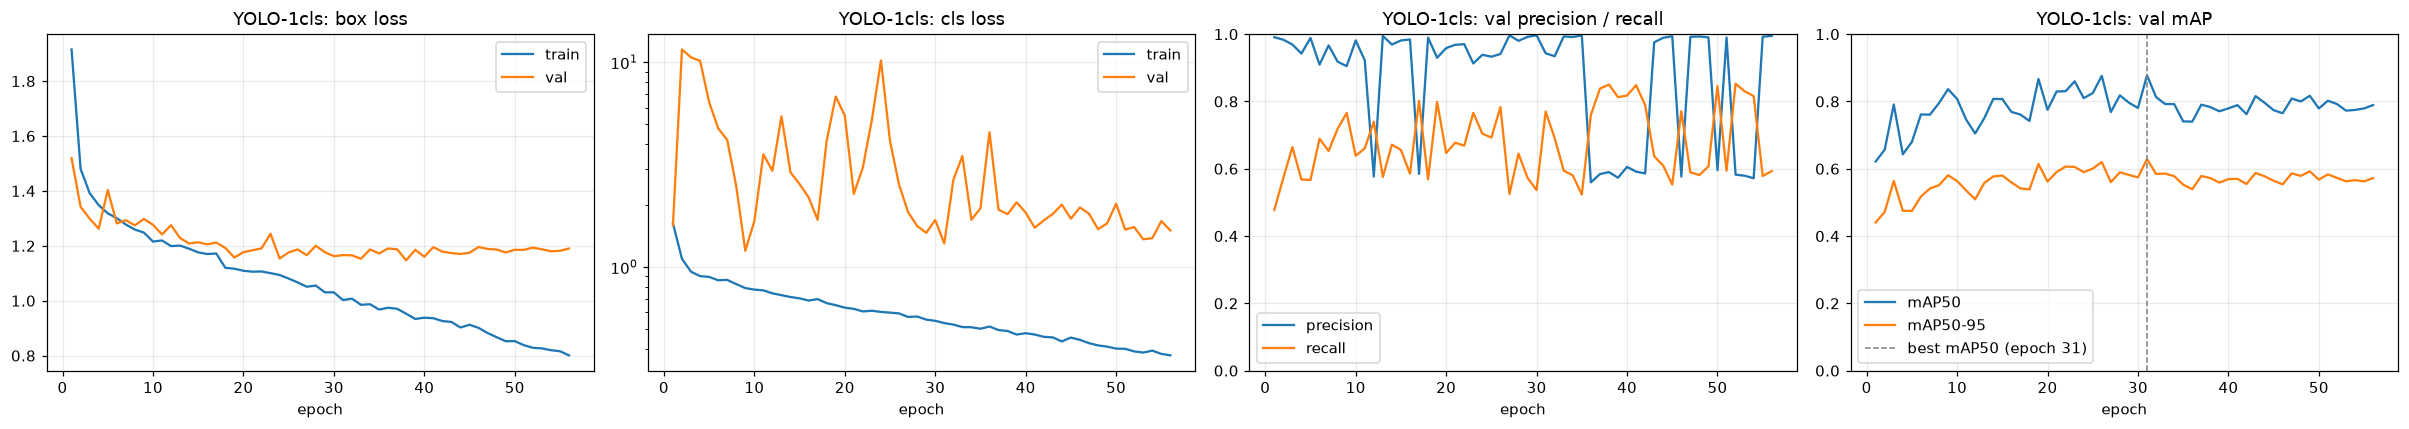

YOLO-1cls: 56 epochs logged, best val mAP50 0.878, mAP50-95 0.629 (epoch 31); last epoch mAP50 0.789


In [4]:
# ---- YOLO training curves from the Ultralytics log (train / val only: these are not test results)
CURVE_COLS = [("train/box_loss", "val/box_loss", "box loss"), ("train/cls_loss", "val/cls_loss", "cls loss")]
for name, sub in (("YOLO", "detector"), ("YOLO-1cls", YOLO_1CLS_RUN)):
    log_file = RUNS / sub / "train" / "results.csv"
    if not log_file.exists():
        print(f"{name}: no training log at {log_file}")
        continue
    hist = pd.read_csv(log_file)
    hist.columns = hist.columns.str.strip()                                  # Ultralytics pads some column names with spaces
    fig, ax = plt.subplots(1, 4, figsize=(22, 4))
    for a, (tr, va, title) in zip(ax[:2], CURVE_COLS):
        a.plot(hist["epoch"], hist[tr], label="train")
        a.plot(hist["epoch"], hist[va], label="val")
        a.set(title=f"{name}: {title}", xlabel="epoch")
        if title == "cls loss":
            a.set_yscale("log")                                              # val cls loss can spike by an order of magnitude
        a.legend()
    for col, label in (("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")):
        ax[2].plot(hist["epoch"], hist[col], label=label)
    ax[2].set(title=f"{name}: val precision / recall", xlabel="epoch", ylim=(0, 1))
    ax[2].legend()
    for col, label in (("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")):
        ax[3].plot(hist["epoch"], hist[col], label=label)
    best = hist["metrics/mAP50(B)"].idxmax()
    ax[3].axvline(hist["epoch"][best], color="gray", ls="--", lw=1, label=f"best mAP50 (epoch {int(hist['epoch'][best])})")
    ax[3].set(title=f"{name}: val mAP", xlabel="epoch", ylim=(0, 1))
    ax[3].legend()
    plt.tight_layout()
    plt.show()
    print(f"{name}: {len(hist)} epochs logged, best val mAP50 {hist['metrics/mAP50(B)'].max():.3f}, "
          f"mAP50-95 {hist['metrics/mAP50-95(B)'].max():.3f} (epoch {int(hist['epoch'][best])}); last epoch mAP50 {hist['metrics/mAP50(B)'].iloc[-1]:.3f}")

In [5]:
BOX_COLS = ["box_x0", "box_y0", "box_x1", "box_y1"]


def gt_arrays(rd, i):
    g = rd.boxes(i)
    return g, g[BOX_COLS].to_numpy()


def add_snr_bin(df, col="snr"):
    df["snr_bin"] = pd.Categorical(snr_bin_labels(df[col]).astype(object), categories=SNR_LABELS, ordered=True)
    return df


def eval_detection(set_name, det_name, thr=0.5, apply_op=True):
    """Match detections to the true boxes (IoU >= thr, one-to-one). Returns (one row per true box, one row per detection)."""
    rd, gt_rows, pr_rows = READERS[set_name], [], []
    for i, dets in enumerate(run_detector(set_name, det_name)):
        if apply_op:
            dets = op_filter(dets, det_name)
        g, gb = gt_arrays(rd, i)
        m = match_detections([d["box"] for d in dets], [d["score"] for d in dets], gb, thr)
        hit = {int(k) for k in m[m >= 0]}
        for k, r in enumerate(g.itertuples()):
            gt_rows.append(dict(scene=i, snr=r.snr_db, burst=r.burst_type, family_id=r.family_id, detected=k in hit))
        for p, d in enumerate(dets):
            row = dict(scene=i, score=d["score"], tp=bool(m[p] >= 0))
            if m[p] >= 0:
                gbox = gb[m[p]]
                (pt0, pt1), (gt0, gt1) = box_times_ms(d["box"]), box_times_ms(gbox)
                row.update(df_hz=box_center_hz(d["box"]) - box_center_hz(gbox), bw_ratio=(d["box"][2] - d["box"][0] + 1) / (gbox[2] - gbox[0] + 1),
                           dt0_ms=pt0 - gt0, dt1_ms=pt1 - gt1)
            pr_rows.append(row)
    return pd.DataFrame(gt_rows), pd.DataFrame(pr_rows)


def det_summary(gt, pr):
    tp = int(pr.tp.sum()) if len(pr) else 0
    fp, fn = len(pr) - tp, len(gt) - int(gt.detected.sum())
    return dict(precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), n_pred=len(pr), n_gt=len(gt))


def pr_curve(set_name, det_name):
    """Greedy matching by descending score is consistent for every score threshold, so one matching gives the whole curve."""
    gt, pr = eval_detection(set_name, det_name, apply_op=False)
    pr = pr.sort_values("score", ascending=False)
    tp = pr.tp.cumsum().to_numpy()
    return tp / np.arange(1, len(pr) + 1), tp / len(gt)


DET_RESULTS = {d: eval_detection("test", d) for d in DETECTORS}
DET_TABLE = pd.DataFrame({d: det_summary(*res) for d, res in DET_RESULTS.items()}).T
print("Detection on the frozen test set (IoU 0.5, YOLO at its operating confidence):")
display(DET_TABLE)


YOLO-1cls on test: 100%|██████████| 24/24 [00:10<00:00,  2.23it/s]


Detection on the frozen test set (IoU 0.5, YOLO at its operating confidence):


,precision,recall,f1,n_pred,n_gt
CFAR,0.090,0.605,0.157,21184.0,3151.0
YOLO-1cls,0.902,0.922,0.912,3222.0,3151.0


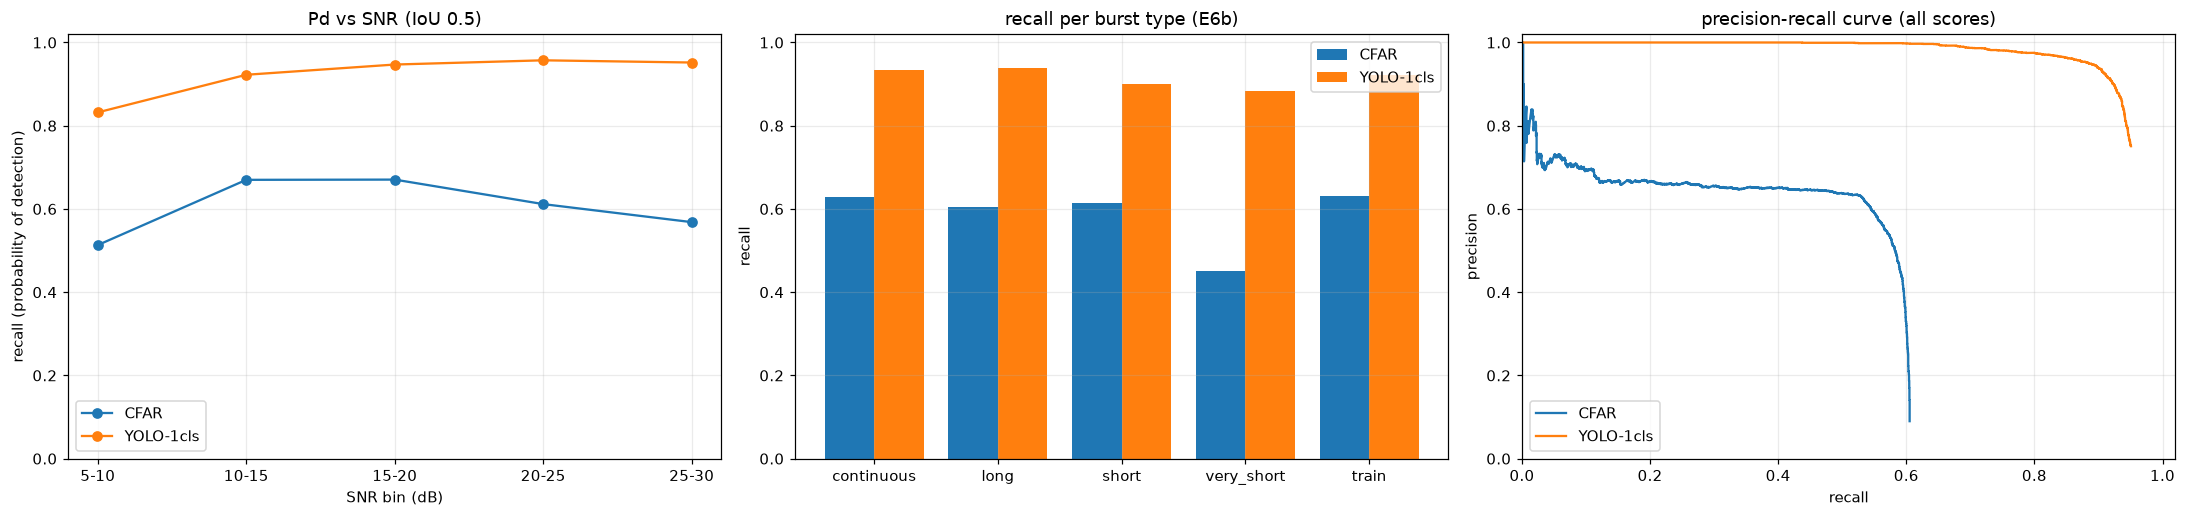

localization error of the matched boxes (test):


,median |center error| (Hz),median |bandwidth ratio - 1|,median |start error| (ms),median |end error| (ms)
CFAR,125.0,0.273,0.0,1.0
YOLO-1cls,0.0,0.032,0.0,0.0


In [6]:
BURSTS = ["continuous", "long", "short", "very_short", "train"]
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
w = 0.8 / len(DET_RESULTS)
for n, (d, (gt, pr)) in enumerate(DET_RESULTS.items()):
    g = add_snr_bin(gt.copy(), "snr")
    ax[0].plot(SNR_LABELS, g.groupby("snr_bin", observed=False).detected.mean().reindex(SNR_LABELS).values, marker="o", label=d)
    ax[1].bar(np.arange(len(BURSTS)) + n * w, gt.groupby("burst").detected.mean().reindex(BURSTS).values, width=w, label=d)
    p, r = pr_curve("test", d)
    ax[2].plot(r, p, label=d)
ax[0].set_xlabel("SNR bin (dB)")
ax[0].set_ylabel("recall (probability of detection)")
ax[0].set_ylim(0, 1.02)
ax[0].set_title("Pd vs SNR (IoU 0.5)")
ax[0].legend()
ax[1].set_xticks(np.arange(len(BURSTS)) + w * (len(DET_RESULTS) - 1) / 2, BURSTS)
ax[1].set_ylabel("recall")
ax[1].set_ylim(0, 1.02)
ax[1].set_title("recall per burst type (E6b)")
ax[1].legend()
ax[2].set_xlabel("recall")
ax[2].set_ylabel("precision")
ax[2].set_xlim(0, 1.02)
ax[2].set_ylim(0, 1.02)
ax[2].set_title("precision-recall curve (all scores)")
ax[2].legend()
plt.tight_layout()
plt.show()

loc = {}
for d, (gt, pr) in DET_RESULTS.items():
    m = pr[pr.tp] if len(pr) and pr.tp.any() else None
    if m is not None:
        loc[d] = {"median |center error| (Hz)": m.df_hz.abs().median(), "median |bandwidth ratio - 1|": (m.bw_ratio - 1).abs().median(),
                  "median |start error| (ms)": m.dt0_ms.abs().median(), "median |end error| (ms)": m.dt1_ms.abs().median()}
print("localization error of the matched boxes (test):")
display(pd.DataFrame(loc).T)


## 3. Modulation-family classification (E3)

Each classifier is run on the **ground-truth boxes** of the frozen `test` set, so the result isolates classification from detection. Reported: accuracy, macro-F1, per-family F1, the coarse-group accuracy (PSK and QAM merged, the level a magnitude spectrogram can realistically separate), confusion matrices and accuracy vs SNR. PSK vs QAM is expected to be the weak point of the spectrogram models.


In [7]:
GT_CACHE = {}


def gt_box_predictions(set_name, clf_name):
    """Run a classifier on the ground-truth boxes of a set. Returns (table: scene, family_id, snr), probabilities, logits (NaN if none)."""
    key = (set_name, clf_name)
    if key not in GT_CACHE:
        rd, fn = READERS[set_name], CLASSIFIERS[clf_name]
        tabs, P, L = [], [], []
        for i in tqdm(range(len(rd)), desc=f"{clf_name} on {set_name}"):
            g = rd.boxes(i)
            if len(g) == 0:
                continue
            boxes = [tuple(int(v) for v in b) for b in g[["box_x0", "box_y0", "box_x1", "box_y1"]].to_numpy()]
            probs, logits = fn(rd.spec_db(i), boxes, rd.iq(i) if CLF_NEEDS_IQ[clf_name] else None)
            P.append(probs)
            L.append(np.full_like(probs, np.nan) if logits is None else logits)
            tabs.append(pd.DataFrame(dict(scene=i, family_id=g.family_id.to_numpy(), snr=g.snr_db.to_numpy())))
        GT_CACHE[key] = (pd.concat(tabs, ignore_index=True), np.concatenate(P), np.concatenate(L))
    return GT_CACHE[key]


COARSE = np.array([0, 1, 1, 2, 2, 3])          # CW | analog (AM, FM) | linear digital (PSK, QAM) | FSK
CLS_RESULTS, rows = {}, {}
for c in CLASSIFIERS:
    df, P, _ = gt_box_predictions("test", c)
    k = df.family_id.to_numpy() <= len(FAMILIES)
    y, yhat = df.family_id.to_numpy()[k] - 1, P[k].argmax(1)
    CLS_RESULTS[c] = cls_metrics(y, yhat, df.snr.to_numpy()[k])
    rows[c] = dict(accuracy=CLS_RESULTS[c]["accuracy"], macro_f1=CLS_RESULTS[c]["macro_f1"],
                   coarse_accuracy=float((COARSE[y] == COARSE[yhat]).mean()), boxes=len(y))
CLS_TABLE = pd.DataFrame(rows).T
display(CLS_TABLE)
print("per-family F1 (test):")
display(pd.DataFrame({c: {f: v["f1"] for f, v in m["per_class"].items()} for c, m in CLS_RESULTS.items()}).rename_axis("family"))


GBM on test: 100%|██████████| 1500/1500 [00:04<00:00, 314.23it/s]


,accuracy,macro_f1,coarse_accuracy,boxes
GBM,0.951,0.951,0.966,3151.0


per-family F1 (test):


,GBM
family,
CW,0.961
AM,0.954
FM,0.961
PSK,0.935
QAM,0.948
FSK,0.949


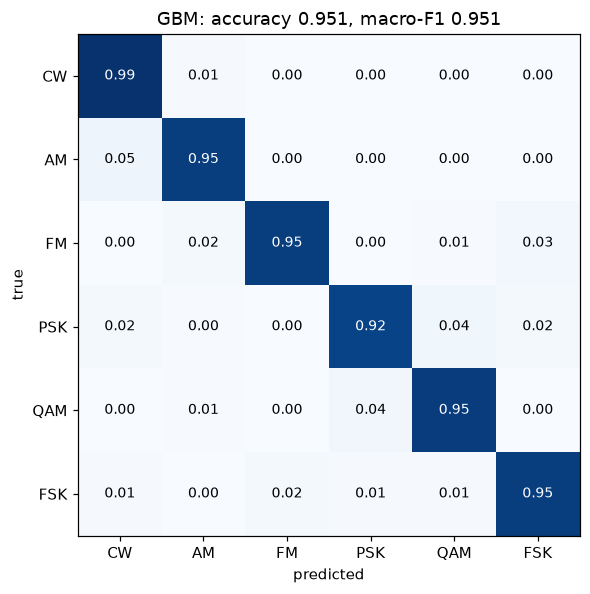

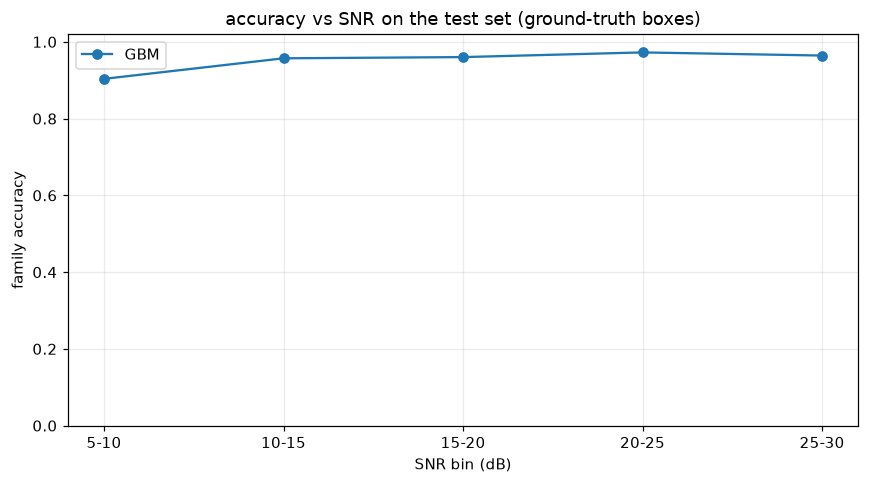

In [8]:
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(6.5 * len(CLASSIFIERS), 5.5), squeeze=False)
for ax, (c, m) in zip(axes[0], CLS_RESULTS.items()):
    cm = np.array(m["confusion"], float)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)                        # rows sum to 1: recall per true family
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.grid(False)
    for i in range(len(FAMILIES)):
        for j in range(len(FAMILIES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(FAMILIES)), FAMILIES)
    ax.set_yticks(range(len(FAMILIES)), FAMILIES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{c}: accuracy {m['accuracy']:.3f}, macro-F1 {m['macro_f1']:.3f}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, m in CLS_RESULTS.items():
    a = m["acc_by_snr"]
    ax.plot(list(a), [v["acc"] for v in a.values()], marker="o", label=c)
ax.set_xlabel("SNR bin (dB)")
ax.set_ylabel("family accuracy")
ax.set_ylim(0, 1.02)
ax.set_title("accuracy vs SNR on the test set (ground-truth boxes)")
ax.legend()
plt.tight_layout()
plt.show()


## 4. End-to-end pipelines

A pipeline is a detector plus a way to assign a family to each detected box:

- **two-stage** `detector + classifier`: the detector gives boxes, the classifier decides the family from a crop around each box (CFAR or YOLO boxes with GBM or ResNet),
- **single-stage** `YOLO (single-stage)`: the 6-class YOLO model predicts box and family together.

A prediction counts as correct only if its box matches a true box at IoU 0.5 **and** its family is right (class-aware F1). The pipeline with the highest class-aware F1 on `test` becomes the **best algorithm** (`BEST`), which Section 10 applies to new samples.


In [9]:
def apply_pipeline(db, iq, pname, dets):
    """Detections of one scene -> [dict(box, score, family = class index, prob)]. The family comes from the classifier
    (two-stage) or from the detector itself (single-stage)."""
    det_name, clf_name = PIPELINES[pname]
    dets = op_filter(dets, det_name)
    if not dets:
        return []
    boxes = [d["box"] for d in dets]
    probs = CLASSIFIERS[clf_name](db, boxes, iq)[0] if clf_name else np.eye(len(FAMILIES))[[d["cls"] for d in dets]]
    return [dict(box=d["box"], score=d["score"], family=int(p.argmax()), prob=float(p.max())) for d, p in zip(dets, probs)]


PIPE_CACHE = {}


def run_pipeline(set_name, pname):
    key = (set_name, pname)
    if key not in PIPE_CACHE:
        det_name, clf_name = PIPELINES[pname]
        rd, dets_all = READERS[set_name], run_detector(set_name, det_name)
        need_iq = clf_name is not None and CLF_NEEDS_IQ[clf_name]
        out = []
        for i in tqdm(range(len(rd)), desc=f"{pname} on {set_name}"):
            if not op_filter(dets_all[i], det_name):
                out.append([])
                continue
            out.append(apply_pipeline(rd.spec_db(i), rd.iq(i) if need_iq else None, pname, dets_all[i]))
        PIPE_CACHE[key] = out
    return PIPE_CACHE[key]


def eval_pipeline(set_name, pname, thr=0.5):
    """Class-aware scores: a matched box with the wrong family counts as one false alarm and one miss."""
    rd = READERS[set_name]
    tp = tpc = n_pred = n_gt = 0
    for i, preds in enumerate(run_pipeline(set_name, pname)):
        g, gb = gt_arrays(rd, i)
        n_gt, n_pred = n_gt + len(g), n_pred + len(preds)
        fam = g.family_id.to_numpy() - 1
        m = match_detections([p["box"] for p in preds], [p["score"] for p in preds], gb, thr)
        for p, k in zip(preds, m):
            if k >= 0:
                tp, tpc = tp + 1, tpc + int(p["family"] == fam[k])
    return dict(det_f1=2 * tp / max(n_pred + n_gt, 1), class_f1=2 * tpc / max(n_pred + n_gt, 1), cls_acc_on_matched=tpc / max(tp, 1),
                n_pred=n_pred, n_gt=n_gt)


PIPE_TABLE = pd.DataFrame({p: eval_pipeline("test", p) for p in PIPELINES}).T
display(PIPE_TABLE.sort_values("class_f1", ascending=False))
BEST = PIPE_TABLE["class_f1"].idxmax()
print(f"best pipeline on the test set (class-aware F1): {BEST}")


YOLO-1cls + GBM on test: 100%|██████████| 1500/1500 [00:04<00:00, 324.19it/s]


,det_f1,class_f1,cls_acc_on_matched,n_pred,n_gt
YOLO-1cls + GBM,0.912,0.856,0.939,3222.0,3151.0
CFAR + GBM,0.157,0.116,0.738,21184.0,3151.0


best pipeline on the test set (class-aware F1): YOLO-1cls + GBM


## 5. The 1 kHz separation test (E1)

`test_1khz` has scenes with exactly two signals at a controlled center-frequency spacing (250 Hz to 10 kHz, 40% at exactly 1 kHz), with bandwidth tiers T1/T2/T3, an SNR sweep and a controlled time overlap.

**Success criterion (R&D Section 6):** both true signals are matched one-to-one to *distinct* detections whose center frequency is within 250 Hz and whose time span overlaps the true burst. The class-aware version also needs the correct family. Failures are split into **merged** (one box covers both signals), **one missed** and **missed**. Detectors are scored on detection alone, pipelines class-aware.


In [10]:
ONE_KHZ = "test_1khz"


def pair_outcome(preds, g, class_aware=False):
    """Success = every true signal is matched one-to-one to a distinct detection: center within +-250 Hz, overlapping in time
    (at least 30% of the true burst) and, if class_aware, with the correct family (R&D Section 6)."""
    gc = g.center_hz.to_numpy()
    g0, g1 = g.t_start_s.to_numpy() * 1e3, g.t_end_s.to_numpy() * 1e3
    gf = g.family_id.to_numpy() - 1
    cost = np.full((max(len(preds), 1), len(g)), 1e9)
    for p, d in enumerate(preds):
        pc, (pt0, pt1) = box_center_hz(d["box"]), box_times_ms(d["box"])
        for k in range(len(g)):
            overlap = min(pt1, g1[k]) - max(pt0, g0[k])
            if abs(pc - gc[k]) <= 250.0 and overlap >= 0.3 * (g1[k] - g0[k]) and (not class_aware or d["family"] == gf[k]):
                cost[p, k] = abs(pc - gc[k])
    matched = 0
    if preds:
        r, c = linear_sum_assignment(cost[:len(preds)])
        matched = int((cost[r, c] < 1e9).sum())
    if matched == len(g):
        return "success"
    for d in preds:                                            # a single box spanning both signals = merged
        lo, hi = (d["box"][0] - N_FFT / 2) * DF, (d["box"][2] + 1 - N_FFT / 2) * DF
        if lo <= gc.min() and hi >= gc.max():
            return "merged"
    return "one missed" if matched == 1 else "missed"


def pair_table(preds_all, class_aware=False):
    rd, rows = READERS[ONE_KHZ], []
    for i, preds in enumerate(preds_all):
        g, s = rd.boxes(i), rd.scenes.iloc[i]
        rows.append(dict(sep_hz=float(s.sep_hz), tier=s.tier_measured, overlap_ms=float(s.overlap_ms), min_snr=float(g.snr_db.min()),
                         n_pred=len(preds), outcome=pair_outcome(preds, g, class_aware)))
    return add_snr_bin(pd.DataFrame(rows), "min_snr")


PAIR = {d: pair_table([op_filter(x, d) for x in run_detector(ONE_KHZ, d)]) for d in DETECTORS}      # detection only
for p in PIPELINES:                                                                                    # detection + correct family
    PAIR[p + " (class-aware)"] = pair_table(run_pipeline(ONE_KHZ, p), class_aware=True)


def summarize_pair(t):
    one = t[t.sep_hz == 1000]
    return {"success @1 kHz": float((one.outcome == "success").mean()), "success (all spacings)": float((t.outcome == "success").mean()),
            "merged @1 kHz": float((one.outcome == "merged").mean()), "a signal missed @1 kHz": float(one.outcome.isin(["one missed", "missed"]).mean()),
            "scenes @1 kHz": len(one)}


ONE_KHZ_TABLE = pd.DataFrame({k: summarize_pair(t) for k, t in PAIR.items()}).T
display(ONE_KHZ_TABLE)


YOLO-1cls + GBM on test_1khz: 100%|██████████| 2000/2000 [00:04<00:00, 428.12it/s]


,success @1 kHz,success (all spacings),merged @1 kHz,a signal missed @1 kHz,scenes @1 kHz
CFAR,0.000,2.850e-02,0.992,0.008,791.0
YOLO-1cls,0.005,1.130e-01,0.833,0.162,791.0
CFAR + GBM (class-aware),0.000,5.000e-04,0.992,0.008,791.0
YOLO-1cls + GBM (class-aware),0.000,6.450e-02,0.834,0.166,791.0


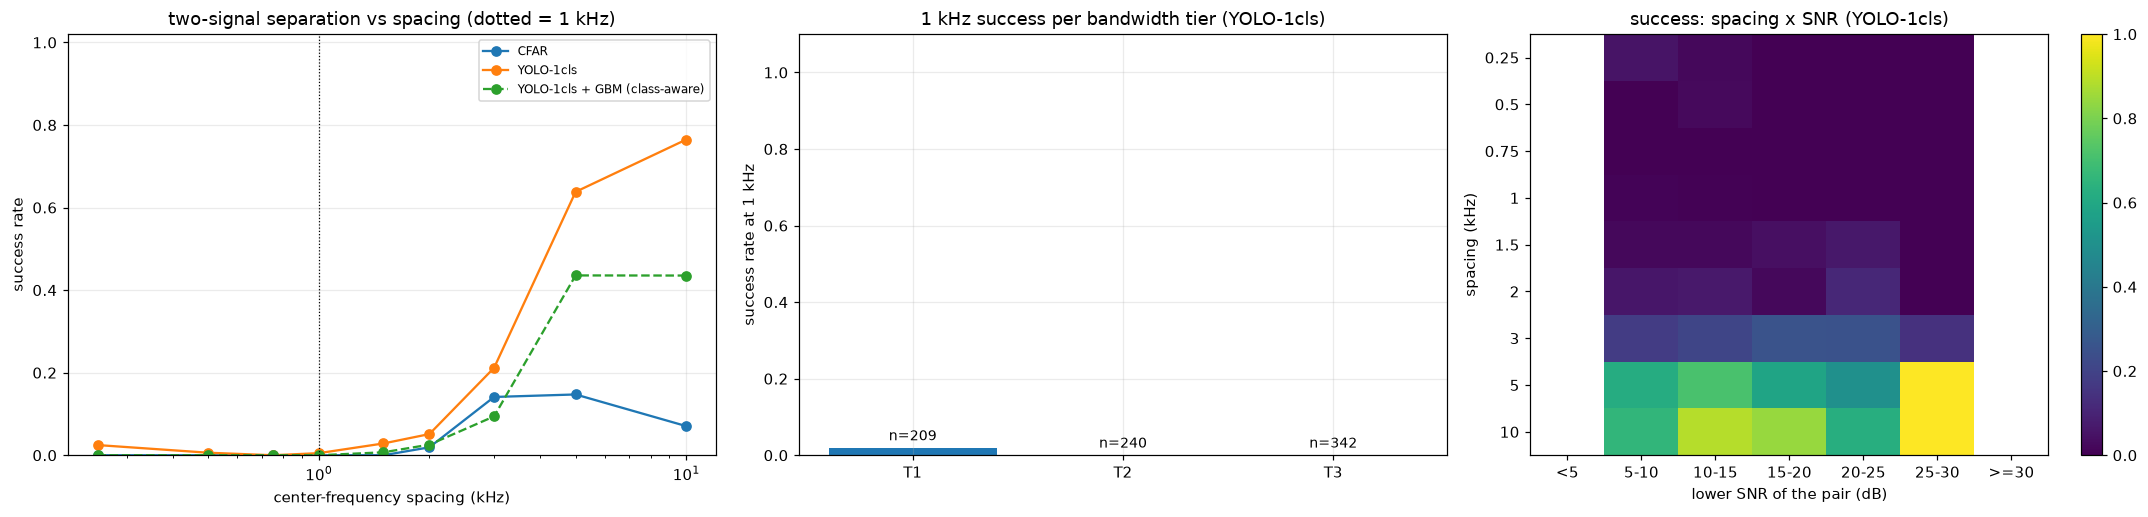

At exactly 1 kHz (YOLO-1cls, detection only):


,success,scenes
lower SNR (dB),,
<5,NaN,0
5-10,0.011,285
10-15,0.005,214
15-20,0.000,171
20-25,0.000,82
25-30,0.000,39
>=30,NaN,0


,success,scenes
time overlap (ms),,
"(0, 5]",0.000,128
"(5, 10]",0.000,110
"(10, 20]",0.000,108
"(20, 40]",NaN,0
"(40, 80]",0.000,126
"(80, 140]",0.013,319


In [11]:
best_det = PIPELINES[BEST][0]
base = PAIR[best_det]                                   # detection only, best detector
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))

for k in list(DETECTORS) + [BEST + " (class-aware)"]:
    t = PAIR[k]
    s = t.assign(ok=t.outcome == "success").groupby("sep_hz").ok.mean()
    ax[0].plot(s.index / 1e3, s.values, marker="o", ls="--" if "class-aware" in k else "-", label=k)
ax[0].axvline(1.0, color="k", lw=0.8, ls=":")
ax[0].set_xscale("log")
ax[0].set_xlabel("center-frequency spacing (kHz)")
ax[0].set_ylabel("success rate")
ax[0].set_ylim(0, 1.02)
ax[0].set_title("two-signal separation vs spacing (dotted = 1 kHz)")
ax[0].legend(fontsize=8)

one = base[base.sep_hz == 1000].assign(ok=lambda d: d.outcome == "success")
by_tier = one.groupby("tier").ok.agg(["mean", "size"])
ax[1].bar(by_tier.index, by_tier["mean"], color="tab:blue")
for i, (m, n) in enumerate(zip(by_tier["mean"], by_tier["size"])):
    ax[1].text(i, m + 0.02, f"n={n}", ha="center", fontsize=9)
ax[1].set_ylim(0, 1.1)
ax[1].set_ylabel("success rate at 1 kHz")
ax[1].set_title(f"1 kHz success per bandwidth tier ({best_det})")

pivot = base.assign(ok=base.outcome == "success").pivot_table(index="sep_hz", columns="snr_bin", values="ok", aggfunc="mean", observed=False)
pivot = pivot.reindex(columns=SNR_LABELS)
im = ax[2].imshow(pivot.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax[2].grid(False)
ax[2].set_xticks(range(len(SNR_LABELS)), SNR_LABELS)
ax[2].set_yticks(range(len(pivot)), [f"{v / 1e3:g}" for v in pivot.index])
ax[2].set_xlabel("lower SNR of the pair (dB)")
ax[2].set_ylabel("spacing (kHz)")
ax[2].set_title(f"success: spacing x SNR ({best_det})")
fig.colorbar(im, ax=ax[2])
plt.tight_layout()
plt.show()

print(f"At exactly 1 kHz ({best_det}, detection only):")
by = lambda g: g.ok.agg(["mean", "size"]).rename(columns={"mean": "success", "size": "scenes"})
display(by(one.groupby("snr_bin", observed=False)).rename_axis("lower SNR (dB)"))
ov = one.assign(overlap=pd.cut(one.overlap_ms, [0, 5, 10, 20, 40, 80, 140]))
display(by(ov.groupby("overlap", observed=False)).rename_axis("time overlap (ms)"))


## 6. Robustness to unseen impairments (E4)

`test_robust` is generated with receiver conditions never used in training: 10 ppm oscillator error, 8-bit ADC and Rayleigh fading. The table compares every detector, classifier and the best pipeline on `test` (seen conditions) and `test_robust`. A large drop means the model depends on the simulator's exact impairments, which is a warning for the sim-to-real step.


YOLO-1cls + GBM on test_robust: 100%|██████████| 1000/1000 [00:04<00:00, 229.45it/s]


set,test,test_robust,change
metric,,,
CFAR: detection F1,0.157,0.131,-0.026
GBM: family accuracy,0.951,0.908,-0.044
YOLO-1cls + GBM (best): class-aware F1,0.856,0.648,-0.208
YOLO-1cls: detection F1,0.912,0.722,-0.190


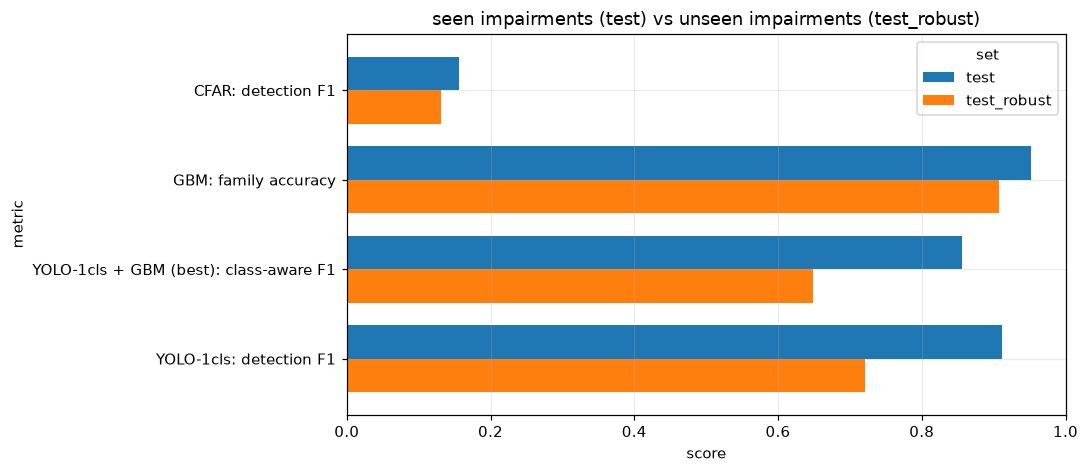

In [12]:
rows = []
for d in DETECTORS:
    for s in ("test", "test_robust"):
        gt, pr = eval_detection(s, d)
        rows.append(dict(metric=f"{d}: detection F1", set=s, value=det_summary(gt, pr)["f1"]))
for c in CLASSIFIERS:
    for s in ("test", "test_robust"):
        df, P, _ = gt_box_predictions(s, c)
        k = df.family_id.to_numpy() <= len(FAMILIES)
        rows.append(dict(metric=f"{c}: family accuracy", set=s, value=float((P[k].argmax(1) == df.family_id.to_numpy()[k] - 1).mean())))
for s in ("test", "test_robust"):
    rows.append(dict(metric=f"{BEST} (best): class-aware F1", set=s, value=eval_pipeline(s, BEST)["class_f1"]))
ROBUST_TABLE = pd.DataFrame(rows).pivot(index="metric", columns="set", values="value")[["test", "test_robust"]]
ROBUST_TABLE["change"] = ROBUST_TABLE["test_robust"] - ROBUST_TABLE["test"]
display(ROBUST_TABLE)

ax = ROBUST_TABLE[["test", "test_robust"]].plot.barh(figsize=(10, 0.6 * len(ROBUST_TABLE) + 2), width=0.75)
ax.set_xlim(0, 1)
ax.set_xlabel("score")
ax.set_title("seen impairments (test) vs unseen impairments (test_robust)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## 7. Open-set: unknown signal classes (E5)

`test_openset` contains OQPSK, 8-FSK and CHIRP, which no model was trained on. A good system should be less confident on them than on the known classes of `test`. The classifier is run on the ground-truth boxes and two scores are compared: **max-softmax** (the baseline) and the **energy score** (logsumexp of the logits, ResNet only). Metrics: AUROC and the false-positive rate (known signals wrongly flagged as unknown) at 95% detection of unknown signals.


GBM on test_openset: 100%|██████████| 1000/1000 [00:03<00:00, 264.99it/s]


,n_known,n_unknown,auroc,fpr_at_95_tpr
method,,,,
GBM (max-softmax),3151,1503,0.796,0.579


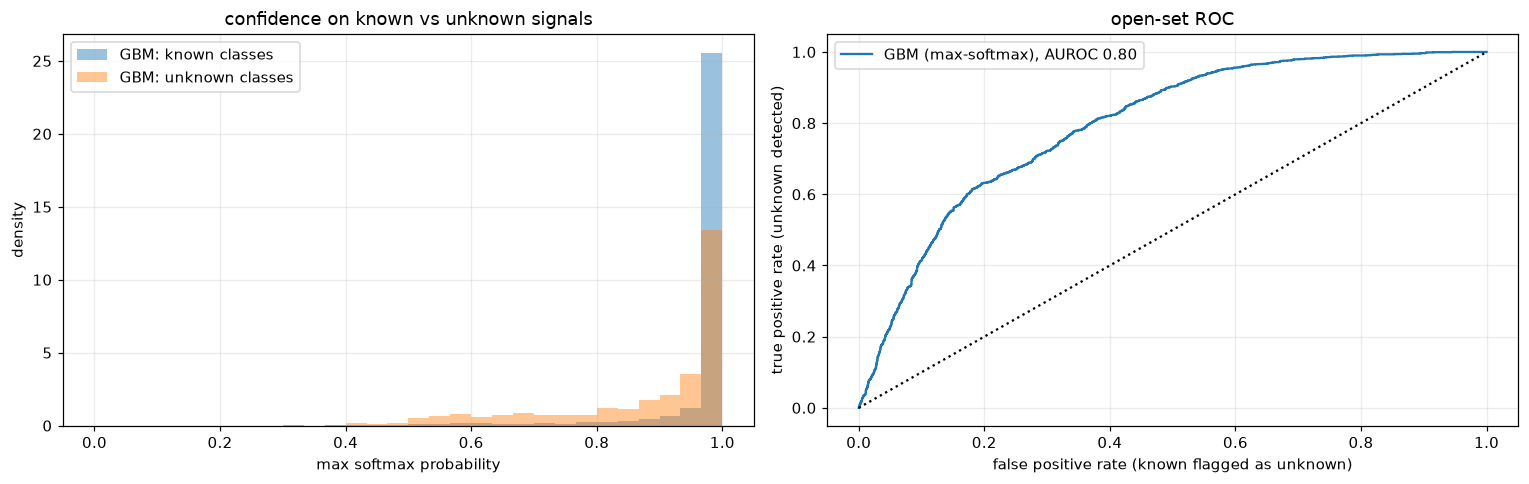

In [13]:
def ood_metrics(s_known, s_unknown):
    """Score: higher = more 'unknown'. Unknown is the positive class."""
    y = np.r_[np.zeros(len(s_known)), np.ones(len(s_unknown))]
    s = np.r_[s_known, s_unknown]
    fpr, tpr, _ = roc_curve(y, s)
    return dict(auroc=float(roc_auc_score(y, s)), fpr_at_95_tpr=float(fpr[np.searchsorted(tpr, 0.95)])), (fpr, tpr)


rows, curves, hists = [], {}, {}
for c in CLASSIFIERS:
    dk, Pk, Lk = gt_box_predictions("test", c)                   # known classes: the main test set
    do, Po, Lo = gt_box_predictions("test_openset", c)           # unknown boxes (OQPSK, 8-FSK, CHIRP) carry family id 7
    kn = dk.family_id.to_numpy() <= len(FAMILIES)
    un = do.family_id.to_numpy() == UNKNOWN_FAMILY_ID
    scores = {"max-softmax": (-Pk[kn].max(1), -Po[un].max(1))}
    if not np.isnan(Lk).any():                                   # the energy score needs logits (ResNet only)
        scores["energy"] = (-logsumexp(Lk[kn], axis=1), -logsumexp(Lo[un], axis=1))
    for name, (sk, su) in scores.items():
        m, curve = ood_metrics(sk, su)
        rows.append(dict(method=f"{c} ({name})", n_known=int(kn.sum()), n_unknown=int(un.sum()), **m))
        curves[f"{c} ({name})"], hists[(c, name)] = curve, (sk, su)
OOD_TABLE = pd.DataFrame(rows).set_index("method")
display(OOD_TABLE)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (c, name), (sk, su) in hists.items():
    if name == "max-softmax":
        ax[0].hist(-sk, bins=30, range=(0, 1), alpha=0.45, density=True, label=f"{c}: known classes")
        ax[0].hist(-su, bins=30, range=(0, 1), alpha=0.45, density=True, label=f"{c}: unknown classes")
ax[0].set_xlabel("max softmax probability")
ax[0].set_ylabel("density")
ax[0].set_title("confidence on known vs unknown signals")
ax[0].legend()
for key, (fpr, tpr) in curves.items():
    ax[1].plot(fpr, tpr, label=f"{key}, AUROC {OOD_TABLE.loc[key, 'auroc']:.2f}")
ax[1].plot([0, 1], [0, 1], "k:")
ax[1].set_xlabel("false positive rate (known flagged as unknown)")
ax[1].set_ylabel("true positive rate (unknown detected)")
ax[1].set_title("open-set ROC")
ax[1].legend()
plt.tight_layout()
plt.show()


## 8. SNR stress: outside the training range

`test_snr_stress` holds scenes with SNR below 5 dB and above 30 dB. Together with `test` (5 to 30 dB) it shows how accuracy and detection recall change with SNR, including the regions the models never saw in training (shaded red). This is for robustness reporting only.


YOLO-1cls on test_snr_stress: 100%|██████████| 16/16 [00:06<00:00,  2.58it/s]


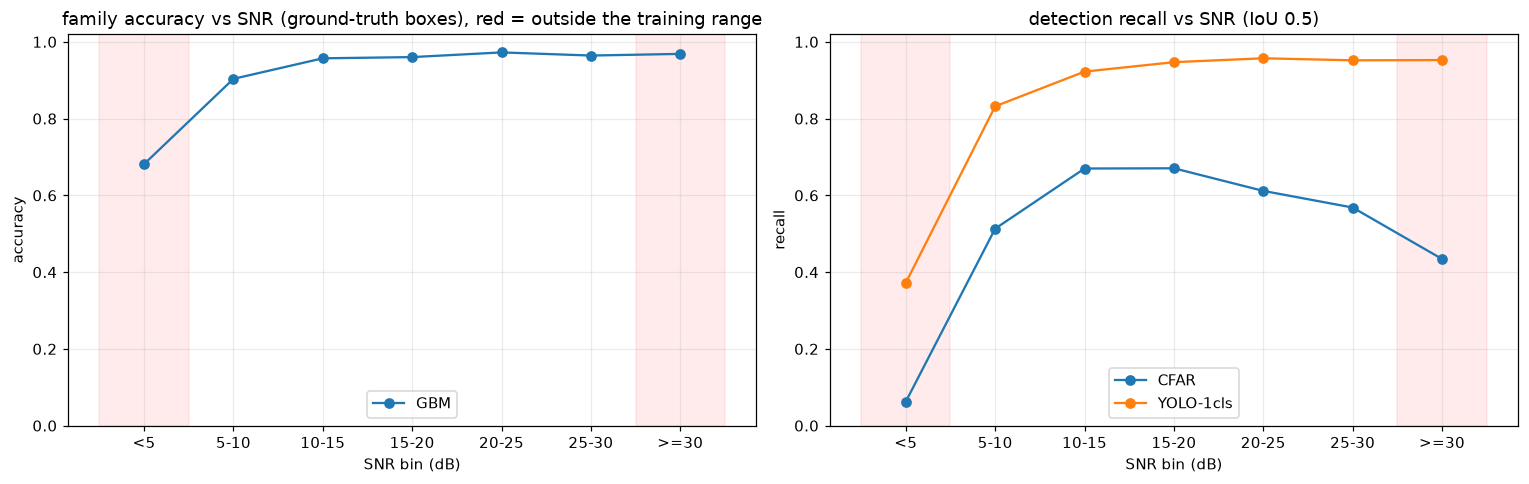

,GBM
SNR bin (dB),
<5,0.681
5-10,0.904
10-15,0.957
15-20,0.960
20-25,0.972
25-30,0.964
>=30,0.969


In [15]:
STRESS = "test_snr_stress"
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
acc_table = {}
for c in CLASSIFIERS:
    parts = []
    for s in ("test", STRESS):                                    # test covers 5 to 30 dB, the stress set the ranges outside
        df, P, _ = gt_box_predictions(s, c)
        k = df.family_id.to_numpy() <= len(FAMILIES)
        parts.append(pd.DataFrame(dict(snr=df.snr.to_numpy()[k], ok=P[k].argmax(1) == df.family_id.to_numpy()[k] - 1)))
    d = add_snr_bin(pd.concat(parts, ignore_index=True), "snr")
    acc_table[c] = d.groupby("snr_bin", observed=False).ok.mean().reindex(SNR_LABELS)
    ax[0].plot(SNR_LABELS, acc_table[c].values, marker="o", label=c)
ax[0].set_title("family accuracy vs SNR (ground-truth boxes), red = outside the training range")
ax[0].set_xlabel("SNR bin (dB)")
ax[0].set_ylabel("accuracy")
ax[0].set_ylim(0, 1.02)
ax[0].legend()

for d_name in DETECTORS:
    g = add_snr_bin(pd.concat([eval_detection(s, d_name)[0] for s in ("test", STRESS)], ignore_index=True), "snr")
    ax[1].plot(SNR_LABELS, g.groupby("snr_bin", observed=False).detected.mean().reindex(SNR_LABELS).values, marker="o", label=d_name)
ax[1].set_title("detection recall vs SNR (IoU 0.5)")
ax[1].set_xlabel("SNR bin (dB)")
ax[1].set_ylabel("recall")
ax[1].set_ylim(0, 1.02)
ax[1].legend()
for a in ax:
    a.axvspan(-0.5, 0.5, color="red", alpha=0.08)
    a.axvspan(5.5, 6.5, color="red", alpha=0.08)
plt.tight_layout()
plt.show()
display(pd.DataFrame(acc_table).rename_axis("SNR bin (dB)"))


## 9. Summary and the best algorithm

All results in one place. The **best algorithm** is the end-to-end pipeline with the highest class-aware F1 on the frozen `test` set (a detection counts only when its box matches at IoU 0.5 **and** its family is correct). It is the algorithm used in the final Test section.


In [14]:
board = PIPE_TABLE.copy()
board["1 kHz success (class-aware)"] = [ONE_KHZ_TABLE.loc[p + " (class-aware)", "success @1 kHz"] for p in board.index]
board = board.sort_values("class_f1", ascending=False)
print("End-to-end leaderboard on the frozen test set (IoU 0.5):")
display(board)
print("\nDetectors (test):")
display(DET_TABLE)
print("\nClassifiers on ground-truth boxes (test):")
display(CLS_TABLE)
print("\nOpen-set (unknown classes):")
display(OOD_TABLE)
print("\nRobustness (seen vs unseen impairments):")
display(ROBUST_TABLE)

print(f"\nBest algorithm: {BEST}  (class-aware F1 {board.loc[BEST, 'class_f1']:.3f}, detection F1 {board.loc[BEST, 'det_f1']:.3f}, "
      f"classification accuracy on matched boxes {board.loc[BEST, 'cls_acc_on_matched']:.3f}, "
      f"1 kHz success {board.loc[BEST, '1 kHz success (class-aware)']:.3f})")
print("Reminder: these numbers come from synthetic data. Validate on real USRP captures before trusting absolute values (R&D Section 8).")

save_json(dict(best_pipeline=BEST, max_scenes=MAX_SCENES, device=str(DEVICE), leaderboard=board.to_dict("index"), detectors=DET_TABLE.to_dict("index"),
               classifiers=CLS_TABLE.to_dict("index"), one_khz=ONE_KHZ_TABLE.to_dict("index"), open_set=OOD_TABLE.to_dict("index"),
               robustness=ROBUST_TABLE.reset_index().to_dict("records")), OUT / "summary.json")
print("saved", OUT / "summary.json")


End-to-end leaderboard on the frozen test set (IoU 0.5):


,det_f1,class_f1,cls_acc_on_matched,n_pred,n_gt,1 kHz success (class-aware)
YOLO-1cls + GBM,0.912,0.856,0.939,3222.0,3151.0,0.0
CFAR + GBM,0.157,0.116,0.738,21184.0,3151.0,0.0



Detectors (test):


,precision,recall,f1,n_pred,n_gt
CFAR,0.090,0.605,0.157,21184.0,3151.0
YOLO-1cls,0.902,0.922,0.912,3222.0,3151.0



Classifiers on ground-truth boxes (test):


,accuracy,macro_f1,coarse_accuracy,boxes
GBM,0.951,0.951,0.966,3151.0



Open-set (unknown classes):


,n_known,n_unknown,auroc,fpr_at_95_tpr
method,,,,
GBM (max-softmax),3151,1503,0.796,0.579



Robustness (seen vs unseen impairments):


set,test,test_robust,change
metric,,,
CFAR: detection F1,0.157,0.131,-0.026
GBM: family accuracy,0.951,0.908,-0.044
YOLO-1cls + GBM (best): class-aware F1,0.856,0.648,-0.208
YOLO-1cls: detection F1,0.912,0.722,-0.190



Best algorithm: YOLO-1cls + GBM  (class-aware F1 0.856, detection F1 0.912, classification accuracy on matched boxes 0.939, 1 kHz success 0.000)
Reminder: these numbers come from synthetic data. Validate on real USRP captures before trusting absolute values (R&D Section 8).
saved /Users/tohid/Desktop/RF-Signal-Detection/runs/evaluation/summary.json


## 10. Test

The best algorithm from Section 9 (chosen on the frozen `test` set by class-aware F1) is applied to **samples that are not in the dataset folder**. They are read from the folder `external_test/` next to this notebook (override with the environment variable `SPECTRUM_EXTERNAL`). The notebook refuses to run if that folder is inside the dataset folder.

**What you can put in `external_test/`**

| File | Meaning |
|---|---|
| `*.npy` complex | raw IQ at 256 kS/s, at least 33536 samples (131 ms) |
| `*.npy` shape `[n, 2]` | raw IQ as I and Q columns |
| `*.cfile` / `*.iq` | raw complex64 from GNU Radio or a USRP capture |
| `*.npy` float `[frames, 1024]` | spectrogram in dB (0 dB = noise floor) |
| `*.png` / `*.jpg` | grayscale spectrogram image, -10 to 40 dB mapped to 0 to 255 (the YOLO export convention) |

For IQ files at another sample rate set `SPECTRUM_INPUT_FS`. The spectrogram of raw IQ is shifted so that its median equals the dataset's noise floor, because a real receiver has an arbitrary gain. A file `<name>.json` next to a sample may hold its ground truth (a list of signals with `kind`, `family`, `center_hz`, `bw_hz`, `t0_ms`, `t1_ms`, `snr_db`).

**If the folder is empty**, three demo scenes are generated into it with a small independent generator (different pulse shaping, audio, burst code and seeds than the dataset generator, so no model has seen them): CW + NBFM + QPSK, 2-FSK + AM + BPSK, and a pair of BPSK signals exactly 1 kHz apart. Their ground truth is drawn as dashed boxes and compared with the prediction. For real captures there is no ground truth, so check the plots by eye.

The demo scenes are cleaner than the dataset (no ADC quantisation, IQ imbalance or fading), and real captures will differ more: this section shows that the full chain runs on new data, it is not a measure of real-world accuracy (R&D Section 8).


In [16]:
from fractions import Fraction

from PIL import Image
from scipy.signal import fftconvolve, firwin, resample_poly

# ------------------------------------------------------------------ where the test samples live (never inside the dataset folder)
EXTERNAL_DIR = Path(os.environ.get("SPECTRUM_EXTERNAL", PROJECT_DIR / "external_test")).resolve()
for forbidden in (ROOT.resolve(), (PROJECT_DIR / "dataset").resolve()):
    if EXTERNAL_DIR == forbidden or forbidden in EXTERNAL_DIR.parents:
        raise ValueError(f"the test samples must be outside the dataset folder ({forbidden})")
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FS = float(os.environ.get("SPECTRUM_INPUT_FS", FS))      # sample rate of your IQ files (resampled to 256 kS/s if different)
SUPPORTED = (".npy", ".cfile", ".iq", ".png", ".jpg", ".jpeg")
# the dataset's noise-floor level: raw IQ has an arbitrary gain, so its spectrogram is shifted until its median matches this value
REF_FLOOR_DB = float(np.median([np.median(READERS["test"].spec_db(i)) for i in range(min(200, len(READERS["test"])))]))


def load_sample(path):
    """Supported inputs:
       .npy complex64/128 (IQ), .npy [n, 2] (I, Q), .cfile / .iq (raw complex64, GNU Radio / USRP), at least 131 ms of IQ at INPUT_FS
       .npy float [frames, 1024] spectrogram in dB (or uint8 as stored in the dataset), .png / .jpg grayscale image (-10..40 dB -> 0..255)
       an optional <name>.json next to the file holds the ground truth (only the generated demo samples have one)."""
    path = Path(path)
    suf, iq, db = path.suffix.lower(), None, None
    if suf == ".npy":
        a = np.load(path)
        if np.iscomplexobj(a):
            iq = a.ravel().astype(np.complex64)
        elif a.ndim == 2 and a.shape[1] == 2:
            iq = (a[:, 0] + 1j * a[:, 1]).astype(np.complex64)
        elif a.ndim == 2:
            db = dequantize_db(a) if a.dtype == np.uint8 else a.astype(np.float32)
        else:
            raise ValueError(f"{path.name}: unsupported array shape {a.shape}")
    elif suf in (".cfile", ".iq"):
        iq = np.fromfile(path, np.complex64)
    elif suf in (".png", ".jpg", ".jpeg"):
        img = Image.open(path).convert("L")
        if img.size != (N_FFT, N_FRAMES):
            img = img.resize((N_FFT, N_FRAMES))
        db = gray_to_db(np.asarray(img))
    else:
        raise ValueError(f"unsupported file type: {path.name}")
    if iq is not None:
        if INPUT_FS != FS:
            fr = Fraction(FS / INPUT_FS).limit_denominator(1000)
            iq = resample_poly(iq, fr.numerator, fr.denominator).astype(np.complex64)
        if len(iq) < N_SAMPLES:
            raise ValueError(f"{path.name}: needs at least {N_SAMPLES} samples ({N_SAMPLES / FS * 1e3:.0f} ms at {FS:.0f} S/s), has {len(iq)}")
        iq = iq[:N_SAMPLES]
        db = spectrogram_db(iq)
        db = db + (REF_FLOOR_DB - float(np.median(db)))
    else:
        if db.shape[1] != N_FFT:
            raise ValueError(f"{path.name}: spectrogram must have {N_FFT} frequency bins, has {db.shape[1]}")
        db = db[:N_FRAMES]
        if db.shape[0] < N_FRAMES:
            db = np.pad(db, ((0, N_FRAMES - db.shape[0]), (0, 0)), constant_values=REF_FLOOR_DB)
    gt_file = path.with_suffix(".json")
    return dict(name=path.stem, db=db.astype(np.float32), iq=iq, gt=json.loads(gt_file.read_text()) if gt_file.exists() else None)


# ------------------------------------------------------------------ demo samples: a small independent generator
# Deliberately different from the dataset generator (low-pass pulse shaping instead of root-raised-cosine, different audio and
# burst code, new seeds, no ADC / IQ imbalance / fading), so these scenes are unseen by every model.
def _audio(n, rng):
    t = np.arange(n) / FS
    a = sum(np.sin(2 * np.pi * f * t + rng.uniform(0, 6.28)) for f in rng.uniform(300, 2500, 3))
    return a / np.abs(a).max()


def _symbols(n, baud, rng, bpsk):
    sps = int(round(FS / baud))
    k = n // sps + 8
    s = rng.choice([-1.0, 1.0], k).astype(complex) if bpsk else (rng.choice([-1.0, 1.0], k) + 1j * rng.choice([-1.0, 1.0], k)) / np.sqrt(2)
    up = np.zeros(k * sps, complex)
    up[::sps] = s
    x = fftconvolve(up, firwin(6 * sps + 1, 0.6 * baud, fs=FS), mode="same")[:n]
    return x / np.sqrt(np.mean(np.abs(x) ** 2))


def _fsk(n, baud, rng):
    sps = int(round(FS / baud))
    f = np.repeat(rng.choice([-1.0, 1.0], n // sps + 2), sps)[:n] * (baud / 2)
    w = np.hanning(max(sps // 2, 2))
    return np.exp(2j * np.pi * np.cumsum(np.convolve(f, w / w.sum(), mode="same")) / FS)


def _baseband(kind, n, rng, baud=None):
    if kind == "CW":
        return np.ones(n, complex)
    if kind == "AM":
        x = 1 + 0.6 * _audio(n, rng)
        return (x / np.sqrt(np.mean(x ** 2))).astype(complex)
    if kind == "NBFM":
        return np.exp(2j * np.pi * 3000 * np.cumsum(_audio(n, rng)) / FS)
    if kind == "BPSK":
        return _symbols(n, baud, rng, True)
    if kind == "QPSK":
        return _symbols(n, baud, rng, False)
    if kind == "2-FSK":
        return _fsk(n, baud, rng)
    raise ValueError(kind)


def _envelope(n, t0_ms, t1_ms, ramp_ms=1.0):
    env = np.zeros(n)
    env[int(t0_ms * FS / 1e3):int(t1_ms * FS / 1e3)] = 1.0
    k = np.hanning(int(ramp_ms * FS / 1e3) * 2 + 1)
    return np.convolve(env, k / k.sum(), mode="same")


FAMILY_OF = {"CW": "CW", "AM": "AM", "NBFM": "FM", "BPSK": "PSK", "QPSK": "PSK", "2-FSK": "FSK"}


def make_demo_scene(signals, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(N_SAMPLES) / FS
    x = (rng.standard_normal(N_SAMPLES) + 1j * rng.standard_normal(N_SAMPLES)) / np.sqrt(2)      # unit-variance noise = 0 dB
    truth = []
    for s in signals:
        amp = np.sqrt(10 ** (s["snr_db"] / 10) * s["bw_hz"] / FS)                                  # in-band SNR over the occupied bandwidth
        x += amp * _envelope(N_SAMPLES, s["t0_ms"], s["t1_ms"]) * _baseband(s["kind"], N_SAMPLES, rng, s.get("baud")) * np.exp(2j * np.pi * s["center_hz"] * t)
        truth.append(dict(s, family=FAMILY_OF[s["kind"]]))
    return x.astype(np.complex64), truth


DEMO_SCENES = {
    "demo_A_cw_nbfm_qpsk": (9001, [dict(kind="CW", center_hz=30e3, bw_hz=500, t0_ms=20, t1_ms=130, snr_db=20),
                                   dict(kind="NBFM", center_hz=-45e3, bw_hz=11e3, t0_ms=10, t1_ms=100, snr_db=22),
                                   dict(kind="QPSK", center_hz=70e3, bw_hz=7.7e3, t0_ms=0, t1_ms=131, snr_db=18, baud=6400)]),
    "demo_B_fsk_am_bpsk": (9002, [dict(kind="2-FSK", center_hz=-80e3, bw_hz=8e3, t0_ms=30, t1_ms=120, snr_db=20, baud=4000),
                                  dict(kind="AM", center_hz=20e3, bw_hz=6e3, t0_ms=0, t1_ms=131, snr_db=25),
                                  dict(kind="BPSK", center_hz=90e3, bw_hz=2.4e3, t0_ms=40, t1_ms=90, snr_db=15, baud=2000)]),
    "demo_C_pair_1khz": (9003, [dict(kind="BPSK", center_hz=40e3, bw_hz=600, t0_ms=10, t1_ms=120, snr_db=22, baud=500),
                                dict(kind="BPSK", center_hz=41e3, bw_hz=600, t0_ms=10, t1_ms=120, snr_db=22, baud=500)]),
}

if not any(p.suffix.lower() in SUPPORTED for p in EXTERNAL_DIR.iterdir()):
    for name, (seed, sigs) in DEMO_SCENES.items():
        iq_demo, truth = make_demo_scene(sigs, seed)
        np.save(EXTERNAL_DIR / f"{name}.npy", iq_demo)
        (EXTERNAL_DIR / f"{name}.json").write_text(json.dumps(truth, indent=1))
    print(f"no samples found: generated {len(DEMO_SCENES)} demo scenes in {EXTERNAL_DIR}")

SAMPLES = [load_sample(p) for p in sorted(EXTERNAL_DIR.iterdir()) if p.suffix.lower() in SUPPORTED]
print(f"{len(SAMPLES)} test sample(s) from {EXTERNAL_DIR}:", [s["name"] for s in SAMPLES])


no samples found: generated 3 demo scenes in /Users/tohid/Desktop/RF-Signal-Detection/external_test
3 test sample(s) from /Users/tohid/Desktop/RF-Signal-Detection/external_test: ['demo_A_cw_nbfm_qpsk', 'demo_B_fsk_am_bpsk', 'demo_C_pair_1khz']


best algorithm: YOLO-1cls + GBM   (detector: YOLO-1cls, classifier: GBM)


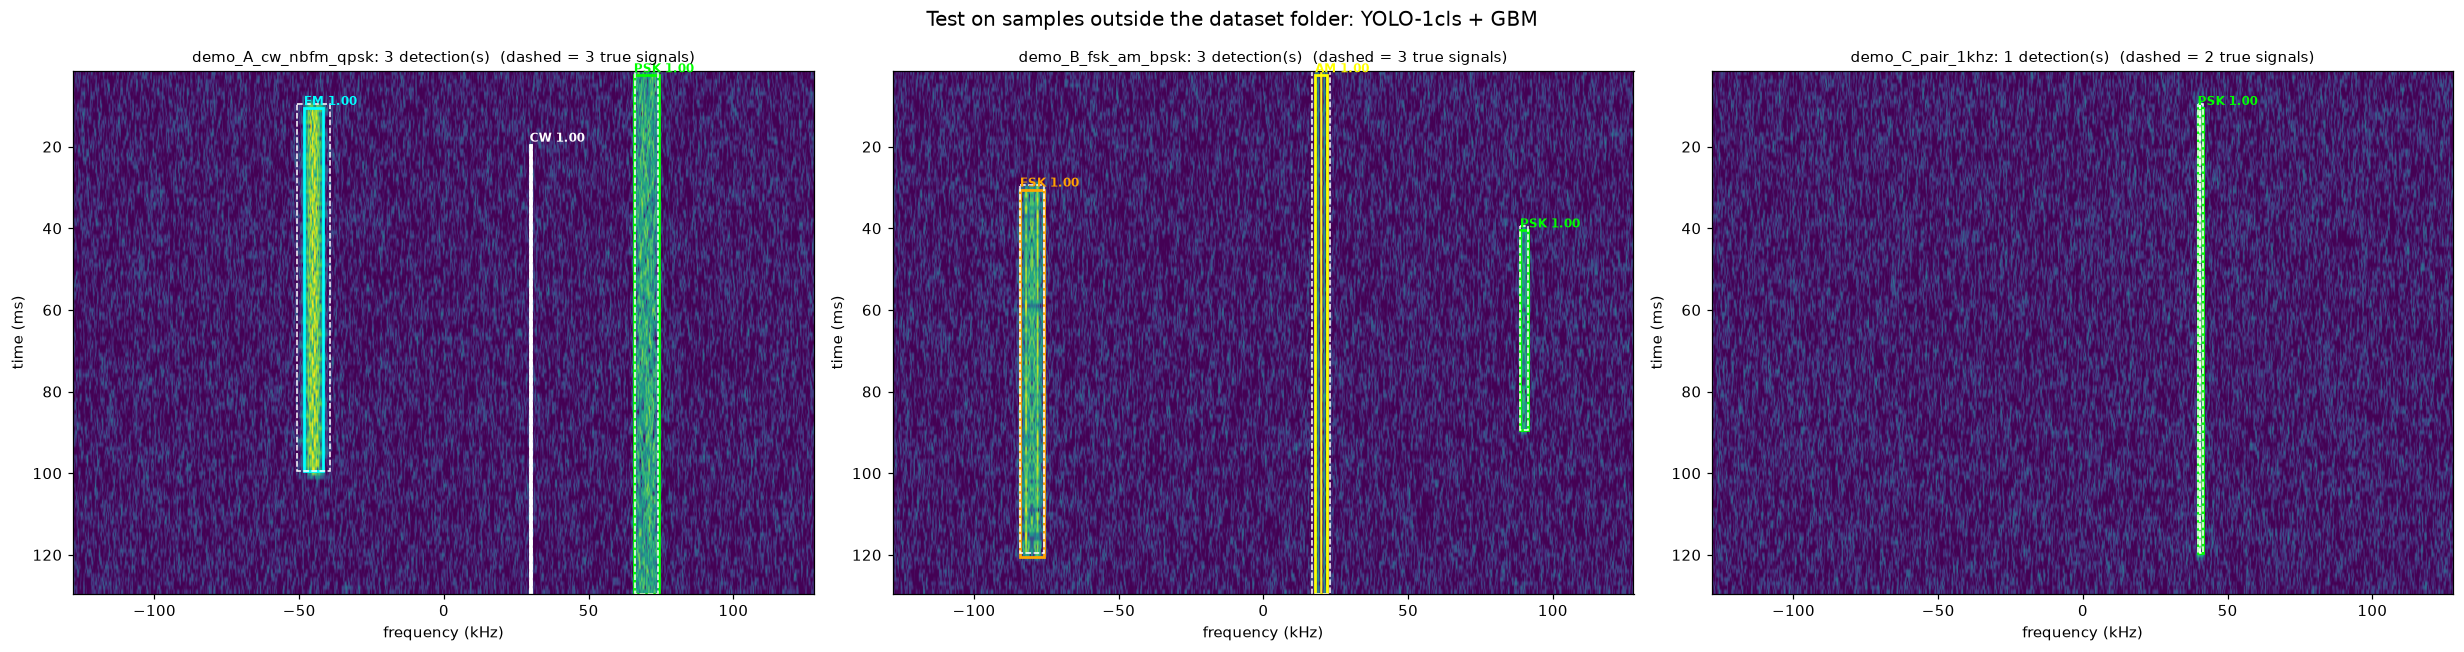

Predictions


,sample,family,class_confidence,detection_score,center_kHz,bandwidth_kHz,start_ms,end_ms
0,demo_A_cw_nbfm_qpsk,PSK,1.000,0.922,70.125,8.75,2.5,129.5
1,demo_A_cw_nbfm_qpsk,FM,0.998,0.890,-44.875,6.75,10.5,99.5
2,demo_A_cw_nbfm_qpsk,CW,0.996,0.523,30.000,0.50,19.5,129.5
3,demo_B_fsk_am_bpsk,FSK,0.999,0.888,-79.875,8.25,30.5,120.5
4,demo_B_fsk_am_bpsk,PSK,1.000,0.863,90.125,2.75,40.5,89.5
5,demo_B_fsk_am_bpsk,AM,0.999,0.858,20.125,4.25,2.5,129.5
6,demo_C_pair_1khz,PSK,0.999,0.732,40.750,2.00,10.5,119.5


Comparison with the ground truth of the demo samples


,sample,true_class,true_family,snr_db,detected,predicted_family,family_correct
0,demo_A_cw_nbfm_qpsk,CW,CW,20.0,True,CW,True
1,demo_A_cw_nbfm_qpsk,NBFM,FM,22.0,True,FM,True
2,demo_A_cw_nbfm_qpsk,QPSK,PSK,18.0,True,PSK,True
3,demo_A_cw_nbfm_qpsk,(false alarms),NaN,NaN,0,NaN,NaN
4,demo_B_fsk_am_bpsk,2-FSK,FSK,20.0,True,FSK,True
5,demo_B_fsk_am_bpsk,AM,AM,25.0,True,AM,True
6,demo_B_fsk_am_bpsk,BPSK,PSK,15.0,True,PSK,True
7,demo_B_fsk_am_bpsk,(false alarms),NaN,NaN,0,NaN,NaN
8,demo_C_pair_1khz,BPSK,PSK,22.0,True,PSK,True
9,demo_C_pair_1khz,BPSK,PSK,22.0,False,-,False


detected 7 of 8 signals, family correct for 7 of 8


In [17]:
BEST_DET, BEST_CLF = PIPELINES[BEST]
print(f"best algorithm: {BEST}   (detector: {BEST_DET}, classifier: {BEST_CLF or 'the detector itself'})")


def predict_sample(sample):
    dets = DETECTORS[BEST_DET].detect(sample["db"])
    return apply_pipeline(sample["db"], sample["iq"], BEST, dets)


def box_to_axes(b):                          # same geometry as plot_scene in 01_create_dataset.ipynb
    return ((b[0] - N_FFT / 2 - 0.5) * DF / 1e3, (b[2] - N_FFT / 2 + 0.5) * DF / 1e3,
            (b[1] * HOP + N_FFT / 2 - HOP / 2) / FS * 1e3, (b[3] * HOP + N_FFT / 2 + HOP / 2) / FS * 1e3)


def gt_to_box(t):                            # ground truth (centre, bandwidth, on-time) -> pixel box
    x0 = int(np.clip(round((t["center_hz"] - t["bw_hz"] / 2) / DF + N_FFT / 2), 0, N_FFT - 1))
    x1 = int(np.clip(round((t["center_hz"] + t["bw_hz"] / 2) / DF + N_FFT / 2), x0, N_FFT - 1))
    y0 = int(np.clip(np.ceil((t["t0_ms"] * FS / 1e3 - N_FFT / 2) / HOP), 0, N_FRAMES - 2))
    y1 = int(np.clip(np.floor((t["t1_ms"] * FS / 1e3 - 1 - N_FFT / 2) / HOP), y0 + 1, N_FRAMES - 1))
    return (x0, y0, x1, y1)


EXTENT = [(-N_FFT / 2 - 0.5) * DF / 1e3, (N_FFT / 2 - 0.5) * DF / 1e3,
          ((N_FRAMES - 1) * HOP + N_FFT / 2 + HOP / 2) / FS * 1e3, (N_FFT / 2 - HOP / 2) / FS * 1e3]

report_rows = []
fig, axes = plt.subplots(1, len(SAMPLES), figsize=(7.5 * len(SAMPLES), 6), squeeze=False)
for ax, s in zip(axes[0], SAMPLES):
    preds = predict_sample(s)
    ax.imshow(s["db"], aspect="auto", extent=EXTENT, cmap="viridis", vmin=-5, vmax=30)
    ax.grid(False)
    for p in preds:
        f0, f1, t0, t1 = box_to_axes(p["box"])
        c = FAM_COLOR[p["family"]]
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec=c, lw=1.8))
        ax.text(f0, t0, f'{FAMILIES[p["family"]]} {p["prob"]:.2f}', color=c, fontsize=8, va="bottom", fontweight="bold")
        report_rows.append(dict(sample=s["name"], family=FAMILIES[p["family"]], class_confidence=p["prob"], detection_score=p["score"],
                                center_kHz=box_center_hz(p["box"]) / 1e3, bandwidth_kHz=(p["box"][2] - p["box"][0] + 1) * DF / 1e3,
                                start_ms=box_times_ms(p["box"])[0], end_ms=box_times_ms(p["box"])[1]))
    title = f'{s["name"]}: {len(preds)} detection(s)'
    if s["gt"]:                                                      # dashed white = ground truth of the demo samples
        for t in s["gt"]:
            f0, f1, t0, t1 = box_to_axes(gt_to_box(t))
            ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="white", lw=1.0, ls="--"))
        title += f'  (dashed = {len(s["gt"])} true signals)'
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("frequency (kHz)")
    ax.set_ylabel("time (ms)")
fig.suptitle(f"Test on samples outside the dataset folder: {BEST}", fontsize=13)
plt.tight_layout()
plt.show()

print("Predictions")
display(pd.DataFrame(report_rows))

# compare with the ground truth where it is known (the generated demo samples)
cmp_rows = []
for s in SAMPLES:
    if not s["gt"]:
        continue
    preds = predict_sample(s)
    gtb = [gt_to_box(t) for t in s["gt"]]
    m = match_detections([p["box"] for p in preds], [p["score"] for p in preds], gtb, thr=0.3)     # IoU 0.3: the truth boxes are approximate
    found = {int(g): p for p, g in enumerate(m) if g >= 0}
    for g, t in enumerate(s["gt"]):
        p = preds[found[g]] if g in found else None
        cmp_rows.append(dict(sample=s["name"], true_class=t["kind"], true_family=t["family"], snr_db=t["snr_db"], detected=p is not None,
                             predicted_family=FAMILIES[p["family"]] if p else "-", family_correct=bool(p and FAMILIES[p["family"]] == t["family"])))
    cmp_rows.append(dict(sample=s["name"], true_class="(false alarms)", detected=int((m < 0).sum())))
if cmp_rows:
    cmp = pd.DataFrame(cmp_rows)
    print("Comparison with the ground truth of the demo samples")
    display(cmp)
    sig = cmp[cmp.true_class != "(false alarms)"]
    print(f"detected {int(sig.detected.sum())} of {len(sig)} signals, family correct for {int(sig.family_correct.sum())} of {len(sig)}")
